# 02. 외부 자료 비교: KRX vs 네이버 vs 야후

- **목표**: 우리가 보정한 KRX 가격이 네이버·야후와 얼마나 맞는지 보고, 무엇을 기준으로 삼고 무엇을 검증용으로 쓸지 정한다.
- 이 노트북은 파일을 **읽기만** 한다.
- 예전 노트북 05(자료 비교)·07(새 야후와 기준가)·08의 1~4절(데이터 선택)을 합쳤다. 예전 야후 폴더 대신 **새 야후(yf)** 를 쓴다.

## 세 자료의 성격 (이 노트북에서 확인한 사실)

| 자료 | 가격의 종류 | 상장폐지 종목 | 배당 |
|---|---|---|---|
| KRX 원자료 + 우리 보정 | 실제 거래 가격 → 우리가 분할·배당·유상·기준가를 보정 | 있음 | DART + 야후(2011~2014) |
| 네이버 | 분할 + **기준가가 바뀐 날(권리락·감자 등) 대부분** 보정. 배당 보정은 없음 | 거의 다 있음 | 없음 |
| 새 야후 `Close` | 분할만 보정 (기준가 사건은 일부만) | **없음** | — |
| 새 야후 `Adj Close` | 분할 + 배당 보정 | **없음** | 실제 배당락일 |

## 공정하게 비교하는 규칙
1. **같은 수준으로 보정된 것끼리** 비교한다. 우리 `close_s`·`close_b` ↔ 네이버·야후 `Close`, 우리 `adj_close` ↔ 야후 `Adj Close`.
   - `close_b` = 분할 + 기준가만 보정한 종가 (= `close_s x base_factor`)
2. **수준** 일치(두 가격이 0.5% 안인 날의 비율)와 **하루 수익률** 일치(차이 0.2%p 안인 날의 비율)를 둘 다 본다.
3. 무작위 표본은 씨앗(seed)을 고정해서 다시 돌려도 같은 결과가 나오게 한다.

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
# (예전 07~09번 노트북은 이 칸이 없어서 "indexbeater 를 찾을 수 없다"는 오류가 났다.)
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from indexbeater.krx_source import paths, external

# 그래프의 한글이 네모(□)로 깨지지 않게 윈도우 기본 한글 글꼴을 쓴다.
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False      # 마이너스(-) 기호가 깨지는 것도 막는다
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # 표의 소수점은 네 자리까지만
from indexbeater.krx_source import compare as C

adj = pd.read_parquet(paths.ADJUSTED, columns=["date", "market", "code", "close", "close_s", "adj_close", "base_factor", "mktcap"])
adj = adj[adj["market"].isin(["KOSPI", "KOSDAQ"])].sort_values(["code", "date"]).reset_index(drop=True)
adj["close_b"] = adj["close_s"] * adj["base_factor"]       # 분할 + 기준가만 보정한 종가
meta = adj.groupby("code").agg(first=("date", "min"), last=("date", "max"), n=("date", "size"),
                               mc=("mktcap", "median"), market=("market", "last")).reset_index()
meta["delisted"] = meta["last"] < adj["date"].max() - pd.Timedelta(days=14)
print("KRX 보통주 종목코드:", len(meta), "(상장폐지", int(meta["delisted"].sum()), ")")
print("네이버 파일:", len(list(paths.NAVER_DIR.glob("*.csv"))), "/ 새 야후 파일:", len(external.yf_index()))

# 새 야후와 우리 가격을 날짜별로 맞춰 붙이는 도구. (compare.compare_naver 와 같은 모양)
def compare_yf(k, code):
    y = external.load_yf(code)
    if y is None:
        return None
    j = k.set_index("date")[["close", "close_s", "close_b", "adj_close"]].join(
        y[["close", "adj_close"]].rename(columns={"close": "yf_close", "adj_close": "yf_adj"}), how="outer")
    j["code"] = code
    return j

KRX 보통주 종목코드: 3527 (상장폐지 752 )
네이버 파일: 3527 / 새 야후 파일: 2765


## 1. 얼마나 넓게 덮고 있나 (커버리지)

- 코스피·코스닥에 있었던 **모든 종목** 중 각 자료가 몇 개를 갖고 있나? 특히 **상장폐지 종목**이 중요하다. 망한 종목이 빠지면 "살아남은 것만 보는" 생존편향이 생겨 백테스트가 실제보다 좋게 나온다.

              KRX  naver  yahoo
group                          
상장중 KOSDAQ   1836   1835   1828
상장중 KOSPI     939    939    936
상장폐지 KOSDAQ   498    498      0
상장폐지 KOSPI    254    254      0


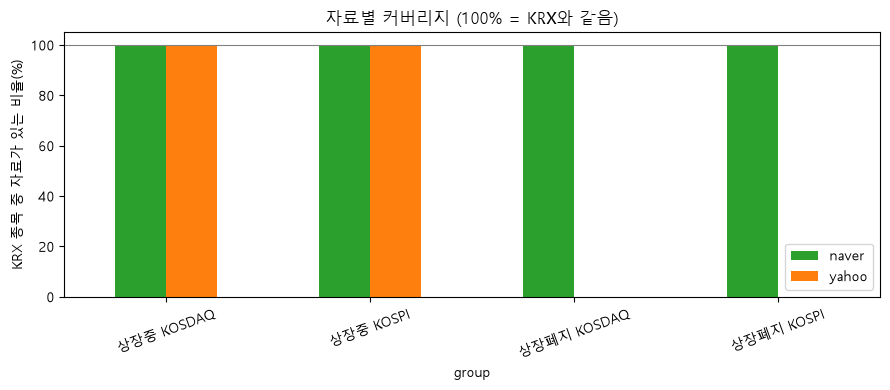

In [3]:
yidx = external.yf_index()
meta["naver"] = [(paths.NAVER_DIR / f"{c}.csv").exists() for c in meta["code"]]
meta["yahoo"] = meta["code"].isin(yidx.keys())
meta["group"] = np.where(meta["delisted"], "상장폐지", "상장중") + " " + meta["market"]
cov = meta.groupby("group")[["naver", "yahoo"]].sum()
cov.insert(0, "KRX", meta.groupby("group").size())
print(cov.to_string())
ax = (cov[["naver", "yahoo"]].div(cov["KRX"], axis=0) * 100).plot(kind="bar", figsize=(9, 4), color=["tab:green", "tab:orange"])
ax.set_ylabel("KRX 종목 중 자료가 있는 비율(%)"); ax.set_title("자료별 커버리지 (100% = KRX와 같음)")
ax.axhline(100, color="gray", lw=0.8); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**읽는 법**: 네이버는 상장폐지 종목까지 거의 다 있다. 야후는 상장폐지가 거의 **0개**다(지금 거래되는 종목만 준다). 야후만 쓰면 망한 종목 수백 개가 통째로 사라진다.

## 2. 새 야후의 열은 무엇인가, 예전 야후 폴더는 필요한가

- 새 야후: `Close` = 분할만 보정, `Adj Close` = 분할+배당 보정.
- 예전 야후 폴더의 `Close` 가 새 야후 `Adj Close` 와 같다면, 예전 폴더는 **중복**이라 더 쓸 필요가 없다.

In [4]:
# 새 야후 파일 600개 중 3개마다 1개씩(200개) 골라, 예전 Close 와 새 Adj Close 가 0.5% 안으로 같은 날의 비율을 센다.
same = tot = 0
for c in list(yidx)[:600:3]:
    a, b = external.load_yahoo(c), external.load_yf(c)
    if a is None or b is None:
        continue
    j = a[["close"]].join(b[["adj_close"]], how="inner").dropna()
    same += ((j["close"] / j["adj_close"] - 1).abs() < 0.005).sum(); tot += len(j)
print(f"예전 야후 Close == 새 야후 Adj Close 일치율: {100 * same / tot:.1f} 퍼센트")
print(external.load_yf("005930").tail(3))

예전 야후 Close == 새 야후 Adj Close 일치율: 99.4 퍼센트
                   open         high          low        close    adj_close  \
date                                                                          
2026-11-17 191,400.0000 195,900.0000 190,100.0000 190,300.0000 190,300.0000   
2026-11-18 196,900.0000 199,950.0000 188,800.0000 194,700.0000 194,700.0000   
2026-11-19 196,000.0000 196,300.0000 189,800.0000 190,400.0000 190,400.0000   

              volume  dividends  stock_splits  
date                                           
2026-11-17  16773338     0.0000        0.0000  
2026-11-18  17692254     0.0000        0.0000  
2026-11-19   3366734     0.0000        0.0000  


## 3. 핵심 발견: 네이버는 '기준가가 바뀐 날'을 보정한다

- KRX 원자료에는 **기준가**가 있다. 기준가가 전날 종가와 다르면 거래소가 그날 가격을 바꿔 준 것이다(권리락·감자·분할합병 등).
- 그런 날 외부 자료의 하루 등락이 (a) **기준가 기준 등락**과 같으면 "보정함", (b) **전일종가 기준 등락**과 같으면 "보정 안 함"이다(허용 0.2%p).

In [5]:
k = pd.read_parquet(paths.RAW_DAILY, columns=["date", "code", "close", "base_price"]).sort_values(["code", "date"])
k["pc"] = k.groupby("code")["close"].shift(); k["r"] = k["base_price"] / k["pc"]
sp = pd.read_csv(paths.SPLIT_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
split_days = set(zip(sp["code"], sp["ex_date"]))
big = k[(k["r"] < 0.95) | (k["r"] > 1.01)].copy()
big = big[[(c, t) not in split_days for c, t in zip(big["code"], big["date"])]]     # 분할일은 뺀다
print("큰 기준가 변동(분할 제외):", len(big), "건,", big["code"].nunique(), "종목")

res, cache = [], {}
for r in big.itertuples():
    row = dict(r=r.r)
    for nm, ld in (("네이버", external.load_naver), ("새 야후 Close", external.load_yf)):
        d = cache.setdefault((nm, r.code), ld(r.code))
        if d is None or r.date not in d.index or d.index.get_loc(r.date) == 0:
            continue
        i = d.index.get_loc(r.date); ret = d["close"].iloc[i] / d["close"].iloc[i - 1]
        row[nm] = "보정함" if abs(ret - r.close / r.base_price) < 0.002 else ("보정 안 함" if abs(ret - r.close / r.pc) < 0.002 else "다른 값")
    res.append(row)
o = pd.DataFrame(res); o["기준가/전일종가"] = pd.cut(o["r"], [0, .9, .95, 1.01, 100])
for nm in ("네이버", "새 야후 Close"):
    print(); print(nm); print(pd.crosstab(o["기준가/전일종가"], o[nm], normalize="index").round(3).to_string())
del k

큰 기준가 변동(분할 제외): 1730 건, 1076 종목



네이버
네이버             다른 값  보정 안 함    보정함
기준가/전일종가                           
(0.0, 0.9]    0.0090  0.0130 0.9780
(0.9, 0.95]   0.0040  0.0180 0.9780
(1.01, 100.0] 0.0100  0.0650 0.9250

새 야후 Close
새 야후 Close      다른 값  보정 안 함    보정함
기준가/전일종가                           
(0.0, 0.9]    0.5250  0.1370 0.3380
(0.9, 0.95]   0.5740  0.0850 0.3410
(1.01, 100.0] 0.2680  0.6110 0.1210


**읽는 법**
- **네이버는 기준가가 크게 바뀐 날의 90% 이상을 보정**했다(하락 쪽 98%, 상승 쪽 93% 안팎).
- 새 야후 `Close` 는 기준가가 내려간 날(권리락·감자 등)의 30%대만 기준가대로 보정했고 절반 넘게는 기준가와도 전일종가와도 다른 값(야후 자체 보정)이다. 기준가가 올라간 날은 60% 넘게 **보정하지 않았다**.
- 그래서 예전 06번 노트북의 "네이버도 야후도 유상증자를 보정하지 않는다"는 결론은 **DART로 추정한 권리락일에서만** 맞았다. 이 발견으로 `base.py` 를 만들어 우리 보정에도 기준가 보정(`base_factor`)을 넣었다.

## 4. 기준가 보정을 넣으니 외부 자료와 더 맞는가 (무작위 500종목)

- 네이버·새 야후가 모두 있는 종목 중 500개를 무작위(씨앗 0)로 뽑아 **종가 수준 일치율**을 잰다.
- 네이버 ↔ `close_s`(분할만) / 네이버 ↔ `close_b`(분할+기준가), 새 야후 `Close` ↔ 같은 둘.
- 네이버는 2026-09-14부터 공식 종가와 다른 값을 주므로(5절) 그 전까지만 비교한다.

표본 종목 492
        naver_s  naver_b   yf_s   yf_b
mean     0.7750   0.8880 0.8090 0.7860
median   1.0000   1.0000 0.9940 0.9940
90퍼센트 이상 일치하는 종목 비율
naver_s   0.6180
naver_b   0.8150
yf_s      0.6590
yf_b      0.6160


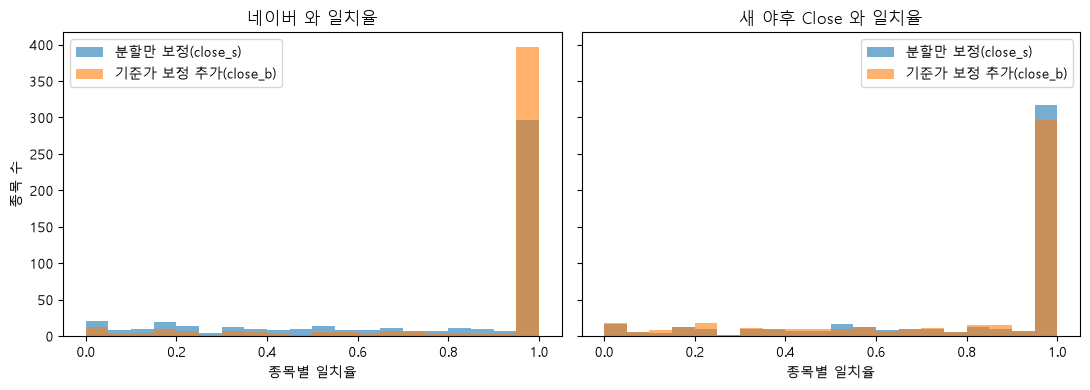

In [6]:
rng = np.random.default_rng(0)
both_codes = [c for c in sorted(meta["code"]) if (paths.NAVER_DIR / f"{c}.csv").exists() and c in yidx]
pick = rng.choice(both_codes, 500, replace=False)
by_all = {c: g.set_index("date") for c, g in adj[adj["code"].isin(pick)].groupby("code")}

def rate(x, y):
    """두 가격이 0.5% 안으로 같은 날의 비율. 겹치는 날이 30일 미만이면 비교하지 않는다."""
    j = pd.concat([x, y], axis=1, join="inner").dropna()
    j = j[j.index < "2026-09-14"]
    return np.nan if len(j) < 30 else ((j.iloc[:, 0] / j.iloc[:, 1] - 1).abs() < 0.005).mean()

rows = []
for c in pick:
    s = by_all[c]; n = external.load_naver(c)["close"]; y = external.load_yf(c)["close"]
    rows.append(dict(code=c, naver_s=rate(n, s["close_s"]), naver_b=rate(n, s["close_b"]),
                     yf_s=rate(y, s["close_s"]), yf_b=rate(y, s["close_b"])))
R = pd.DataFrame(rows).dropna()
print("표본 종목", len(R))
print(R[["naver_s", "naver_b", "yf_s", "yf_b"]].agg(["mean", "median"]).round(3).to_string())
print("90퍼센트 이상 일치하는 종목 비율")
print((R[["naver_s", "naver_b", "yf_s", "yf_b"]] >= 0.9).mean().round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a_, (c1, c2, t) in zip(ax, [("naver_s", "naver_b", "네이버"), ("yf_s", "yf_b", "새 야후 Close")]):
    a_.hist(R[c1], bins=20, alpha=.6, label="분할만 보정(close_s)"); a_.hist(R[c2], bins=20, alpha=.6, label="기준가 보정 추가(close_b)")
    a_.set_title(t + " 와 일치율"); a_.set_xlabel("종목별 일치율"); a_.legend()
ax[0].set_ylabel("종목 수"); plt.tight_layout(); plt.show()

**읽는 법**: 오른쪽(1.0)에 몰릴수록 두 자료가 같다.
- 네이버는 `close_b`(기준가 보정 추가)와 훨씬 잘 맞는다(90% 이상 일치하는 종목 비율 약 62% → 82%). 기준가 보정이 맞는 방향이라는 증거다.
- 새 야후 `Close` 는 기준가 보정을 넣으면 오히려 조금 **덜** 맞는다(약 66% → 62%). 3절에서 본 것처럼 야후가 기준가 사건을 우리·네이버와 다르게 처리하기 때문이다. 그래서 분할·기준가 검증에는 네이버를 쓴다.

## 5. 네이버 자세히: 하루 수익률, 2026-09-14 이후, 남은 '계단'

- 대표 종목 표본(`compare.select_sample`: 상장 중 대·중·소형, 상장폐지, 분할 경험, 배당 많은 종목. 씨앗 42)으로 본다.
- 하루 수익률 일치율을 연도별·일자별로 본다. 한 번에 평균 내면 문제가 생긴 시기가 묻힌다.

표본 종목 수: 141
why
분할 경험            23
배당 다수            22
상장중 KOSPI 소형     12
상장중 KOSPI 대형     12
상장폐지 KOSPI       12
상장중 KOSPI 중형     12
상장폐지 KOSDAQ      12
상장중 KOSDAQ 중형    12
상장중 KOSDAQ 소형    12
상장중 KOSDAQ 대형    12



네이버가 있는 표본 종목: 141 / 141
하루 수익률 일치율(전체): 0.9884  / 2026-09-14 이전만: 0.9988
일자별 일치율이 처음 60% 아래로 떨어진 날: 2026-09-14


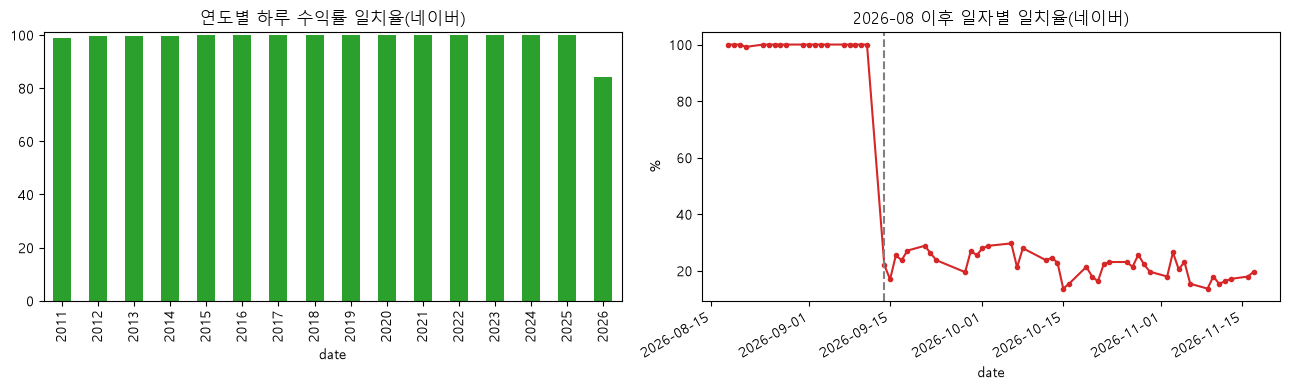

In [7]:
dv = pd.read_csv(paths.DIV_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
dv_codes = set(dv.groupby("code").size().loc[lambda s: s >= 8].index)
m2 = meta[["code", "market", "first", "last", "n", "mc"]].copy()
for c in ("first", "last"):
    m2[c] = m2[c].astype(str).str[:10]
smp = C.select_sample(m2, set(sp["code"]), dv_codes)
print("표본 종목 수:", len(smp)); print(smp["why"].str.split(" / ").str[0].value_counts().to_string())
by = {c: g for c, g in adj[adj["code"].isin(set(smp["code"]) | {"005930"})].groupby("code")}   # 삼성전자는 예시용

rows, rets, joined = [], [], {}
for c in smp["code"]:
    j = C.compare_naver(by[c], c)
    if j is None:
        continue
    joined[c] = j
    rows.append({"code": c, **C.match_stats(j, "close_s", "naver")})
    r = C.return_match(j, "close_s", "naver"); r["code"] = c; rets.append(r)
nv = pd.DataFrame(rows); nr = pd.concat(rets)
print()
print("네이버가 있는 표본 종목:", len(nv), "/", len(smp))
print("하루 수익률 일치율(전체):", round(nr["ok"].mean(), 4), " / 2026-09-14 이전만:", round(nr.loc[nr.index < "2026-09-14", "ok"].mean(), 4))
yr = nr.groupby(nr.index.year)["ok"].mean()

d = nr[nr.index >= "2026-08-15"].groupby(level=0)["ok"].mean() * 100
first_bad = d[d < 60].index.min()
print("일자별 일치율이 처음 60% 아래로 떨어진 날:", first_bad.date())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(yr * 100).plot(kind="bar", ax=ax[0], color="tab:green"); ax[0].set_ylim(0, 101); ax[0].set_title("연도별 하루 수익률 일치율(네이버)")
d.plot(ax=ax[1], color="tab:red", marker="o", ms=3); ax[1].axvline(first_bad, color="gray", ls="--")
ax[1].set_title("2026-08 이후 일자별 일치율(네이버)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**읽는 법**
- 하루 수익률은 거의 다 같다(2026-09-14 이전 99.9%). 단 **2026-09-14부터** 일자별 일치율이 60% 아래로 뚝 떨어진다(오른쪽 그림). 같은 날인데 종가가 다르다(삼성전자도 수백~수천 원). 원인은 이 자료만으로 단정할 수 없다(시간외·대체거래소 가격이 섞였을 가능성은 **확인 못 함**).
- 결론: 2026-09-14 이후 구간은 네이버를 쓰지 않고 **KRX 값을 쓴다**.

In [8]:
# '계단': (네이버 ÷ 우리 close_s) 비율이 하루에 1.5% 넘게 바뀐 날. 과거 가격 전체를 한 번에 옮긴 보정의 흔적이다.
# 계단이 기준가 이벤트(±3일)로 설명되는지 본다.
base_ev = pd.read_csv(paths.BASE_EVENTS, dtype={"code": str}, parse_dates=["ex_date"])
base_by = base_ev.groupby("code")["ex_date"].apply(list).to_dict()
steps = []
for c, j in joined.items():
    jj = j.dropna(subset=["close_s", "naver"]); jj = jj[jj.index < "2026-09-14"]
    if len(jj) < 10:
        continue
    ratio = jj["naver"] / jj["close_s"]; chg = ratio / ratio.shift() - 1
    for dt, v in chg[chg.abs() > 0.015].items():
        near = any(abs((dt - e).days) <= 3 for e in base_by.get(c, []))
        steps.append((c, dt, v, near))
st = pd.DataFrame(steps, columns=["code", "date", "ratio_chg", "기준가_이벤트_근처"])
print("계단 개수:", len(st), " 종목 수:", st["code"].nunique())
print("기준가 이벤트(±3일)로 설명되는 계단 비율:", round(st["기준가_이벤트_근처"].mean(), 3))
st.groupby("기준가_이벤트_근처")["ratio_chg"].describe().round(4)

계단 개수: 114  종목 수: 52
기준가 이벤트(±3일)로 설명되는 계단 비율: 0.64


,count,mean,std,min,25%,50%,75%,max
기준가_이벤트_근처,,,,,,,,
False,41.0000,-0.0068,0.1101,-0.2921,-0.0469,0.0350,0.0471,0.3031
True,73.0000,0.0462,0.8632,-0.9333,-0.1903,0.0681,0.1256,6.4118


**읽는 법**: 예전 05번 노트북은 계단의 절반을 "원인 불명"이라고 했다. 지금 보면 계단의 약 3분의 2가 기준가 이벤트 ±3일 안에 있다. 이것들은 네이버가 기준가 사건을 보정한 흔적이고, 우리 `close_b`·`adj_close` 에는 이미 들어가 있다. 나머지 약 3분의 1은 여전히 **원인 미확인**이다(남은 과제).

## 6. 새 야후 `Adj Close` vs 우리 `adj_close` (분할+배당)

- 야후는 상장폐지 종목이 없어서 표본 중 해당 종목은 빠진다.
- (a) 하루 수익률 일치율 (b) 누적 가격 비율(마지막 날 = 1로 맞춘 뒤 야후 ÷ 우리)이 과거로 갈수록 벌어지는 정도.
- 우리 `adj_close` 에는 유상증자·기준가 보정까지 들어 있고 야후 `Adj Close` 에는 일부만 있어서, 그런 날에는 차이가 나는 것이 정상이다.

새 야후가 있는 표본 종목: 117 / 141
하루 수익률 일치율: 0.9881  날짜 수 343,498
가장 오래된 날 누적 비율(야후/우리, 1이면 같음): 중앙값 1.0  5%~95%: 0.602 ~ 1.087


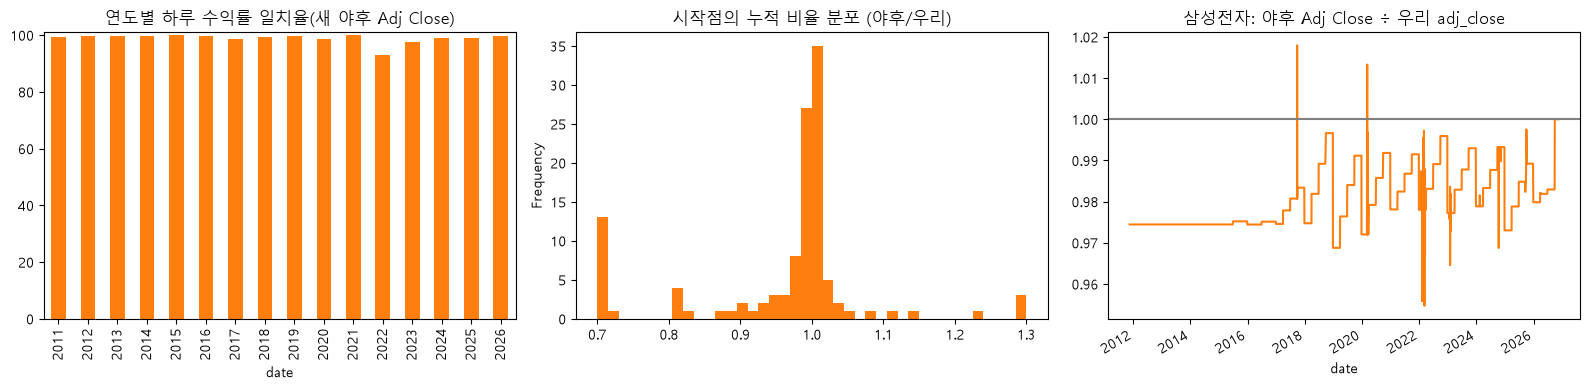

In [9]:
yrets, ratios, yrows = [], {}, []
for c in smp["code"]:
    j = compare_yf(by[c], c)
    if j is None:
        continue
    jj = j.dropna(subset=["adj_close", "yf_adj"])
    if len(jj) < 10:
        continue
    yrows.append({"code": c, **C.match_stats(j, "adj_close", "yf_adj")})
    r = C.return_match(j, "adj_close", "yf_adj"); r["code"] = c; yrets.append(r)
    ratios[c] = (jj["yf_adj"] / jj["yf_adj"].iloc[-1]) / (jj["adj_close"] / jj["adj_close"].iloc[-1])
yv = pd.DataFrame(yrows); yr_ = pd.concat(yrets); Rr = pd.DataFrame(ratios)
first = Rr.apply(lambda s: s.dropna().iloc[0])
print("새 야후가 있는 표본 종목:", len(yv), "/", len(smp))
print("하루 수익률 일치율:", round(yr_["ok"].mean(), 4), " 날짜 수", f"{len(yr_):,}")
print("가장 오래된 날 누적 비율(야후/우리, 1이면 같음): 중앙값", round(first.median(), 4),
      " 5%~95%:", round(first.quantile(.05), 3), "~", round(first.quantile(.95), 3))

j = compare_yf(by["005930"], "005930").dropna(subset=["adj_close", "yf_adj"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
(yr_.groupby(yr_.index.year)["ok"].mean() * 100).plot(kind="bar", ax=ax[0], color="tab:orange"); ax[0].set_ylim(0, 101)
ax[0].set_title("연도별 하루 수익률 일치율(새 야후 Adj Close)")
first.clip(0.7, 1.3).plot(kind="hist", bins=40, ax=ax[1], color="tab:orange"); ax[1].set_title("시작점의 누적 비율 분포 (야후/우리)")
(j["yf_adj"] / j["yf_adj"].iloc[-1] / (j["adj_close"] / j["adj_close"].iloc[-1])).plot(ax=ax[2], color="tab:orange")
ax[2].axhline(1, color="gray"); ax[2].set_title("삼성전자: 야후 Adj Close ÷ 우리 adj_close")
plt.tight_layout(); plt.show()

**읽는 법**: 하루 수익률은 대부분 같다. 누적하면 일부 종목에서 벌어지는데, 확인된 이유는 ① DART는 연간 합계라 우리는 연말 한 번에 빼고 야후는 실제 분기 배당락일마다 뺀다 ② 2026 사업연도 배당은 아직 DART에 없다 ③ 우리는 유상증자·기준가 보정까지 넣었다. 야후의 배당 **날짜**는 우리보다 정확하지만, 계산이 안 보이고(블랙박스) 상장폐지 종목이 없다.

## 7. 분할과 배당을 야후와 맞춰 보기

- **분할**: 야후 `Stock Splits` 와 우리 분할 목록을 **±3일** 안에서 짝짓는다. 공정하게 우리 자료 기간(2011-11-17~)과 우리 기준(주식 수 1.3배 이상 변화)에 맞는 야후 이벤트만 센다.
- **배당**: 같은 달력 연도의 야후 배당 ÷ 전날 `close_s` 의 합(야후 배당수익률)과 우리 DART 배당수익률(1 - factor)을 비교한다. ±20%(상대 차이) 안이면 "맞음".

In [10]:
both = only_o = only_y = 0
for c in yv["code"]:
    y = external.load_yf(c)
    ye = y.loc[(y["stock_splits"] != 0) & (y.index >= "2011-11-17") & ((y["stock_splits"] >= 1.3) | (y["stock_splits"] <= 1 / 1.3)), "stock_splits"]
    oe = sp[sp["code"] == c]; used = set()
    for dt, v in ye.items():
        hit = oe[(oe["ex_date"] - dt).abs() <= pd.Timedelta(days=3)]
        if len(hit):
            both += 1; used.update(hit.index)
        else:
            only_y += 1
    only_o += len(oe) - len(used)
print("분할: 둘 다", both, "/ 야후만", only_y, "/ 우리만", only_o)
print("  야후가 잡은 것 중 우리도 잡은 비율(놓치지 않았나):", round(both / max(1, both + only_y), 3))
print("  우리가 잡은 것 중 야후도 잡은 비율(없는 분할을 만들지 않았나):", round(both / max(1, both + only_o), 3))

ev = dv[dv["code"].isin(yv["code"])].copy()
ev["year"] = ev["ex_date"].dt.year; ev["ours_yield"] = 1 - ev["factor"]
ylds, diffs = {}, []
for c in ev["code"].unique():
    y = external.load_yf(c); pc = by[c].set_index("date")["close_s"].shift()
    dd = y.loc[y["dividends"] > 0, "dividends"]
    yy = (dd / pc.reindex(dd.index)).dropna()
    ylds[c] = yy.groupby(yy.index.year).sum()
ev["yahoo_yield"] = [ylds[c].get(yr0, 0.0) for c, yr0 in zip(ev["code"], ev["year"])]
ev["ratio"] = ev["ours_yield"] / ev["yahoo_yield"].replace(0, np.nan)
ev["ok"] = (ev["ratio"] - 1).abs() <= 0.2
print()
print("배당 금액: 우리(DART)가 야후와 ±20% 안으로 맞은 비율")
print(ev.groupby("confidence").agg(건수=("ok", "size"), 맞음=("ok", "mean"), 야후배당없음=("yahoo_yield", lambda s: (s == 0).mean())).round(3).to_string())

# 배당락일 오차: 12월 결산 회사에서 야후 12월 배당일 - 우리 추정일
for _, r in ev[ev["confidence"] == "estimated"].iterrows():
    y = external.load_yf(r["code"])
    dd = y.loc[(y["dividends"] > 0) & (y.index.year == r["year"]) & (y.index.month == 12)]
    if len(dd):
        diffs.append((dd.index[-1] - r["ex_date"]).days)
x = pd.Series(diffs)
print("배당락일: 비교", len(x), "건 / 같은 날", round((x == 0).mean(), 3), "/ ±3일 안", round((x.abs() <= 3).mean(), 3))

분할: 둘 다 72 / 야후만 25 / 우리만 20
  야후가 잡은 것 중 우리도 잡은 비율(놓치지 않았나): 0.742
  우리가 잡은 것 중 야후도 잡은 비율(없는 분할을 만들지 않았나): 0.783



배당 금액: 우리(DART)가 야후와 ±20% 안으로 맞은 비율
             건수     맞음  야후배당없음
confidence                    
estimated   459 0.9650  0.0000
low         198 0.8180  0.0960


배당락일: 비교 458 건 / 같은 날 0.998 / ±3일 안 1.0


**읽는 법**
- 분할은 두 자료가 4건 중 3건 정도 서로 확인해 준다. 야후만 있는 것은 우리가 놓쳤거나 야후가 다른 종류의 사건(작은 무상증자 등)을 적은 것일 수 있어 단정하지 않는다. 우리만 있는 것은 야후가 기준가 사건을 다르게 처리한 것일 수 있다(3절).
- 배당 **금액**은 `estimated` 에서 95% 이상 맞는다. 12월 결산 회사의 배당락일 추정("연말 직전 거래일")도 야후 날짜와 거의 모두 같은 날이었다. `low`(2023 이후)의 맞음 비율이 낮으면 날짜가 해를 넘겨 생긴 차이일 가능성이 크다. 그래도 `low` 를 통째로 빼면 최근 배당이 빠지므로, 뺀 버전과 넣은 버전을 둘 다 돌려 비교한다.

## 8. 결론 — 무엇을 기준으로, 무엇을 검증용으로

| 용도 | 쓸 자료 | 이유 |
|---|---|---|
| **기준 가격(본체)** | **KRX 원자료 + 우리 보정** (`krx_adjusted.parquet`) | 전 종목·상장폐지 포함, 거래량·상장주식수·기준가·시가총액·거래대금이 함께 있고, 보정 과정을 모두 재현할 수 있다 |
| 분할·기준가 사건 검증 | 네이버 (2026-09-13까지) | 분할과 기준가 사건을 90% 이상 반영한 값이라 `close_s`·`close_b` 의 검산 도구 |
| 배당 보정 검증 | 새 야후 `Adj Close` | 배당까지 보정한 유일한 외부 자료. 배당 날짜가 정확 |
| 쓰지 않음 | 예전 야후 폴더 | 새 야후 `Adj Close` 와 같은 내용(중복) |
| 쓰지 않음 | 야후 단독 | 상장폐지 종목이 없어 생존편향 |

- 네이버·야후는 **정답이 아니라 검산 도구**다. 정답은 거래소 공식 종가와 공시 사실이다.
- 우리 보정이 네이버와 맞지 않는 종목은 03번 노트북의 품질 표시(`krx_quality_flags.csv`)로 관리한다.